<a href="https://colab.research.google.com/github/Komal5578/DWM/blob/main/OLAP_USING_PYTHON_EXP3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas openpyxl matplotlib

In [ ]:
import pandas as pd
xl = pd.ExcelFile("/content/Practice_olap Sample_dataset (1).xlsx")
print(xl.sheet_names)

['Orders']


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_excel("/content/Practice_olap Sample_dataset (1).xlsx", sheet_name="Orders")
df.columns = [c.strip() for c in df.columns]
print(df.columns.tolist())
print(df.head())

['Row ID', 'OrderID', 'OrderDate', 'ShipDate', 'ShipMode', 'CustomerID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
   Row ID         OrderID  OrderDate             ShipDate        ShipMode  \
0       1  CA-2016-152156 2016-11-08  2016-11-11 00:00:00    Second Class   
1       2  CA-2016-152156 2016-11-08  2016-11-11 00:00:00    Second Class   
2       3  CA-2016-138688 2016-06-12  2016-06-16 00:00:00    Second Class   
3       4  US-2015-108966 2015-10-11  2015-10-18 00:00:00  Standard Class   
4       5  US-2015-108966 2015-10-11  2015-10-18 00:00:00  Standard Class   

  CustomerID    Customer Name    Segment        Country             City  ...  \
0   CG-12520      Claire Gute   Consumer  United States        Henderson  ...   
1   CG-12520      Claire Gute   Consumer  United States        Henderson  ...   
2   DV-13045  Darrin Van Huff  Corporat

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_excel("/content/Practice_olap Sample_dataset (1).xlsx", sheet_name="Orders")
df.columns = [c.strip() for c in df.columns]
print(df.columns.tolist())

['Row ID', 'OrderID', 'OrderDate', 'ShipDate', 'ShipMode', 'CustomerID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_excel("/content/Practice_olap Sample_dataset (1).xlsx", sheet_name="Orders")
df.columns = [c.strip() for c in df.columns]

df["OrderDate"] = pd.to_datetime(df["OrderDate"])
df["Year"] = df["OrderDate"].dt.year
df["Quarter"] = df["OrderDate"].dt.quarter
df["MonthNum"] = df["OrderDate"].dt.month
df["Month"] = df["OrderDate"].dt.strftime("%b")
df["Week"] = df["OrderDate"].dt.isocalendar().week

os.makedirs("outputs", exist_ok=True)
print(df.head())

   Row ID         OrderID  OrderDate             ShipDate        ShipMode  \
0       1  CA-2016-152156 2016-11-08  2016-11-11 00:00:00    Second Class   
1       2  CA-2016-152156 2016-11-08  2016-11-11 00:00:00    Second Class   
2       3  CA-2016-138688 2016-06-12  2016-06-16 00:00:00    Second Class   
3       4  US-2015-108966 2015-10-11  2015-10-18 00:00:00  Standard Class   
4       5  US-2015-108966 2015-10-11  2015-10-18 00:00:00  Standard Class   

  CustomerID    Customer Name    Segment        Country             City  ...  \
0   CG-12520      Claire Gute   Consumer  United States        Henderson  ...   
1   CG-12520      Claire Gute   Consumer  United States        Henderson  ...   
2   DV-13045  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   SO-20335   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   SO-20335   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

                                        Product Na

In [ ]:
base_cube = pd.pivot_table(df, index=["Year","Quarter","Month"], columns="Category", values="Sales", aggfunc="sum", fill_value=0)
print(base_cube.head(15))

Category             Furniture  Office Supplies  Technology
Year Quarter Month                                         
2014 1       Feb     1839.6580         1071.724    1608.510
             Jan     6242.5250         4851.080    3143.290
             Mar    14573.9560         8605.879   32511.174
     2       Apr     7944.8370        11155.074    9195.434
             Jun    13206.1256        12953.037    8435.965
             May     6912.7870         7135.624    9599.876
     3       Aug     7320.3465        11379.462    9209.660
             Jul    10821.0510        15121.208    8004.134
             Sep    23816.4808        27423.298   30537.572
     4       Dec    30645.9665        18006.462   20893.192
             Nov    21564.8727        26862.436   30201.408
             Oct    12304.2470         7211.128   11938.018
2015 1       Feb     3134.3740         5368.067    3448.970
             Jan    11739.9416         1808.780    4625.354
             Mar    12499.7830        15

In [ ]:
rollup = pd.pivot_table(df, index="Year", columns="Category", values="Sales", aggfunc="sum", fill_value=0)
print(rollup)

Category    Furniture  Office Supplies  Technology
Year                                              
2014      157192.8531       151776.412  175278.233
2015      170518.2370       137233.463  162780.809
2016      198901.4360       183939.982  226364.180
2017      215387.2692       246097.175  271730.811


In [ ]:
print("TASK 1 - DRILL-DOWN (back to Year>Quarter>Month x Category)")
print(base_cube.head(15))

TASK 1 - DRILL-DOWN (back to Year>Quarter>Month x Category)
Category             Furniture  Office Supplies  Technology
Year Quarter Month                                         
2014 1       Feb     1839.6580         1071.724    1608.510
             Jan     6242.5250         4851.080    3143.290
             Mar    14573.9560         8605.879   32511.174
     2       Apr     7944.8370        11155.074    9195.434
             Jun    13206.1256        12953.037    8435.965
             May     6912.7870         7135.624    9599.876
     3       Aug     7320.3465        11379.462    9209.660
             Jul    10821.0510        15121.208    8004.134
             Sep    23816.4808        27423.298   30537.572
     4       Dec    30645.9665        18006.462   20893.192
             Nov    21564.8727        26862.436   30201.408
             Oct    12304.2470         7211.128   11938.018
2015 1       Feb     3134.3740         5368.067    3448.970
             Jan    11739.9416         1

In [ ]:
slice_west = pd.pivot_table(df[df["Region"]=="West"], index=["Year","Quarter","Month"], columns="Category", values="Sales", aggfunc="sum", fill_value=0)
print(slice_west.head(15))

Category             Furniture  Office Supplies  Technology
Year Quarter Month                                         
2014 1       Feb      144.1280          673.858     239.970
             Jan     1158.4350         1780.288       0.000
             Mar     3920.7320         4677.706    2410.460
     2       Apr     3531.1010         1051.858    4760.528
             Jun     3425.5480         3784.786    2419.088
             May     1864.3820         1204.246    3501.810
     3       Aug     1600.7000         5643.143    6004.388
             Jul     6792.2710        10830.418    4185.864
             Sep     7086.8540         4158.276    3655.407
     4       Dec    11461.7925         8498.291    5496.322
             Nov     6038.6385         7995.758    9157.228
             Oct     3057.8660         2548.226    3122.666
2015 1       Feb      376.3840          888.874     538.920
             Jan     3635.3140          471.446    1919.976
             Mar     6559.9480         2

In [ ]:
dice = pd.pivot_table(
    df[df["Region"].isin(["West","East"]) & df["Category"].isin(["Furniture","Technology"])],
    index=["Year","Quarter","Month"], columns=["Region","Category"],
    values="Sales", aggfunc="sum", fill_value=0
)
print(dice.head(15))

Region                   East                   West           
Category            Furniture Technology   Furniture Technology
Year Quarter Month                                             
2014 1       Feb        0.000    115.360    144.1280    239.970
             Jan      199.004    124.200   1158.4350      0.000
             Mar     4273.374    647.100   3920.7320   2410.460
     2       Apr      929.414    368.672   3531.1010   4760.528
             Jun     3672.689   3693.837   3425.5480   2419.088
             May     2433.143   3098.954   1864.3820   3501.810
     3       Aug     2010.402    741.360   1600.7000   6004.388
             Jul     1386.670   1654.214   6792.2710   4185.864
             Sep    10015.199   6837.014   7086.8540   3655.407
     4       Dec     7264.888  11978.674  11461.7925   5496.322
             Nov     8322.296  15757.086   6038.6385   9157.228
             Oct     6725.660    462.258   3057.8660   3122.666
2015 1       Feb     2137.542   1235.910

In [ ]:
task2 = pd.pivot_table(
    df, index=["Region","Year","Quarter","Month"], columns="Category",
    values=["Sales","Profit"], aggfunc="sum", fill_value=0
)
print(task2.head(10))


                              Profit                                 Sales  \
Category                   Furniture Office Supplies Technology  Furniture   
Region  Year Quarter Month                                                   
Central 2014 1       Feb     64.0797          1.9794   228.7476   439.3100   
                     Jan     20.9235         87.8167     9.7500   506.3580   
                     Mar   -305.2842       -226.9871   258.2246  3639.2900   
             2       Apr   -243.3865        178.8450   293.9202  1468.2180   
                     Jun    325.2257        987.4609   -66.5648  4284.0466   
                     May   -401.3119       -257.2424   152.5372  2304.3820   
             3       Aug     58.5440        201.7774   368.1054   964.4820   
                     Jul   -273.1140      -3816.9578    34.7380  2185.8960   
                     Sep   -253.4921       3668.3760 -1992.0867  6189.8278   
             4       Dec    233.0964        211.5323   443.2184 

            Sales      Profit  Sales Growth %  Profit Growth %
Year                                                          
2014  484247.4981  49543.9741             NaN              NaN
2015  470532.5090  61618.6037           -2.83            24.37
2016  609205.5980  81795.1743           29.47            32.74
2017  733215.2552  93439.2696           20.36            14.24


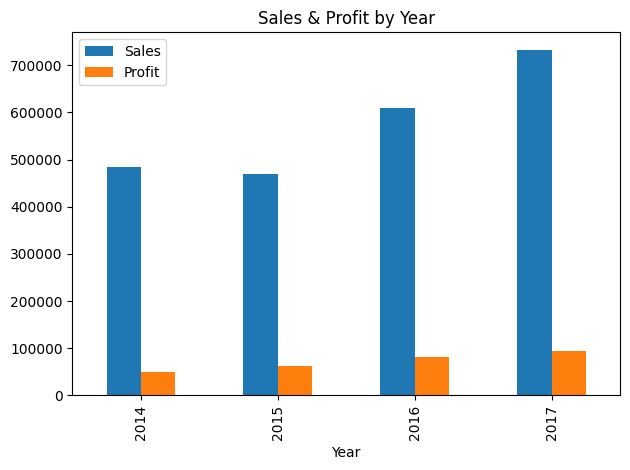

In [ ]:
task3 = df.groupby("Year").agg(Sales=("Sales","sum"), Profit=("Profit","sum"))
task3["Sales Growth %"] = task3["Sales"].pct_change().mul(100).round(2)
task3["Profit Growth %"] = task3["Profit"].pct_change().mul(100).round(2)
print(task3)

task3[["Sales","Profit"]].plot(kind="bar", title="Sales & Profit by Year")
plt.tight_layout()
plt.show()

In [ ]:
PRODUCT_NAME = "Staples"  # change to a real product name from your data
task4 = df[df["Product Name"]==PRODUCT_NAME].groupby(["Year","MonthNum","Month"]).agg(Sales=("Sales","sum"))
print(task4)

                      Sales
Year MonthNum Month        
2014 2        Feb    12.350
     3        Mar    18.936
     4        Apr    30.992
     5        May     7.104
     6        Jun    27.392
     10       Oct    16.012
     11       Nov    54.304
     12       Dec     7.860
2015 3        Mar    50.424
     4        Apr    18.416
     8        Aug    12.032
     9        Sep     4.512
     11       Nov     3.008
     12       Dec    30.060
2016 2        Feb    36.480
     4        Apr    31.560
     7        Jul    20.440
     8        Aug    11.680
     9        Sep    43.836
     10       Oct    25.248
     11       Nov    58.368
2017 1        Jan    23.010
     2        Feb    30.888
     3        Mar     3.760
     5        May     7.410
     8        Aug    24.320
     9        Sep    14.820
     10       Oct    54.456
     11       Nov    36.480
     12       Dec    39.312


In [ ]:
task5 = pd.pivot_table(df, index="Sub-Category", columns="Region", values="Quantity", aggfunc="sum", fill_value=0)
task5["Grand Total"] = task5.sum(axis=1)
task5 = task5.sort_values("Grand Total", ascending=False)
print(task5)

Region        Central  East  South  West  Grand Total
Sub-Category                                         
Binders          1473  1652    981  1868         5974
Paper            1225  1400    851  1702         5178
Furnishings       758  1015    615  1175         3563
Phones            713   982    526  1068         3289
Storage           724   907    488  1039         3158
Art               678   849    547   926         3000
Accessories       716   724    504  1032         2976
Chairs            615   676    331   734         2356
Appliances        470   474    293   492         1729
Labels            284   420    216   480         1400
Tables            262   271    227   481         1241
Fasteners         227   298    126   263          914
Envelopes         206   267    206   227          906
Bookcases         192   252    118   306          868
Supplies          122   195     92   238          647
Machines           66   165     62   147          440
Copiers            49    71 

                          Sales     Profit
Year MonthNum Month                       
2014 1        Jan    14236.8950  2450.1907
     2        Feb     4519.8920   862.3084
     3        Mar    55691.0090   498.7299
     4        Apr    28295.3450  3488.8352
     5        May    23648.2870  2738.7096
     6        Jun    34595.1276  4976.5244
     7        Jul    33946.3930  -841.4826
     8        Aug    27909.4685  5318.1050
     9        Sep    81777.3508  8328.0994
     10       Oct    31453.3930  3448.2573
     11       Nov    78628.7167  9292.1269
     12       Dec    69545.6205  8983.5699
2015 1        Jan    18174.0756 -3281.0070
     2        Feb    11951.4110  2813.8508
     3        Mar    38726.2520  9732.0978


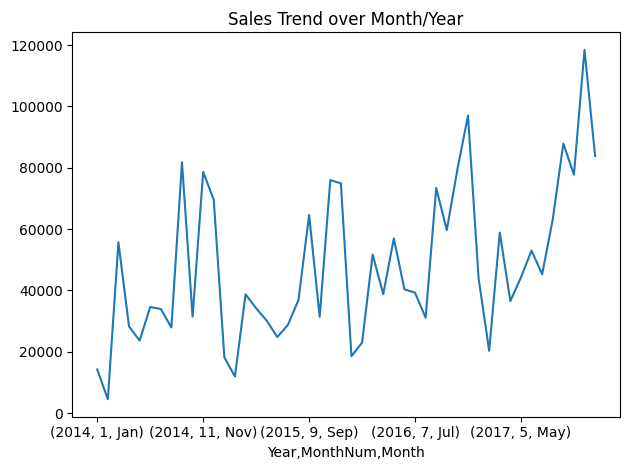

In [ ]:
task6 = df.groupby(["Year","MonthNum","Month"]).agg(Sales=("Sales","sum"), Profit=("Profit","sum"))
print(task6.head(15))

task6["Sales"].plot(title="Sales Trend over Month/Year")
plt.tight_layout()
plt.show()


In [ ]:
task7 = pd.pivot_table(df[df["Year"]==2015], index="City", columns="Category", values="Sales", aggfunc="sum", fill_value=0)
print(task7.head(10))

Category    Furniture  Office Supplies  Technology
City                                              
Akron           0.000           31.590     395.958
Alexandria    192.220            0.000       0.000
Allen         244.006           24.720      21.480
Allentown       0.000          815.716      21.728
Altoona         0.000           20.451       0.000
Amarillo     2453.430            0.000     571.048
Anaheim      1101.620          234.732       0.000
Ann Arbor       0.000          240.163     649.110
Arlington    1089.565         2467.466    2513.790
Atlanta       129.930         7373.220     251.910


In [ ]:
task8 = pd.pivot_table(df[df["Month"]=="Jan"], index="Year", columns="Category", values="Sales", aggfunc="sum", fill_value=0)
print(task8)

Category   Furniture  Office Supplies  Technology
Year                                             
2014       6242.5250         4851.080    3143.290
2015      11739.9416         1808.780    4625.354
2016       7622.7430         5299.682    5620.066
2017       5964.0320        21274.289   16733.053


Category              Furniture  Technology
Year MonthNum Month                        
2014 1        Jan     6242.5250    3143.290
     2        Feb     1839.6580    1608.510
     3        Mar    14573.9560   32511.174
     4        Apr     7944.8370    9195.434
     5        May     6912.7870    9599.876
     6        Jun    13206.1256    8435.965
     7        Jul    10821.0510    8004.134
     8        Aug     7320.3465    9209.660
     9        Sep    23816.4808   30537.572
     10       Oct    12304.2470   11938.018
     11       Nov    21564.8727   30201.408
     12       Dec    30645.9665   20893.192
2015 1        Jan    11739.9416    4625.354


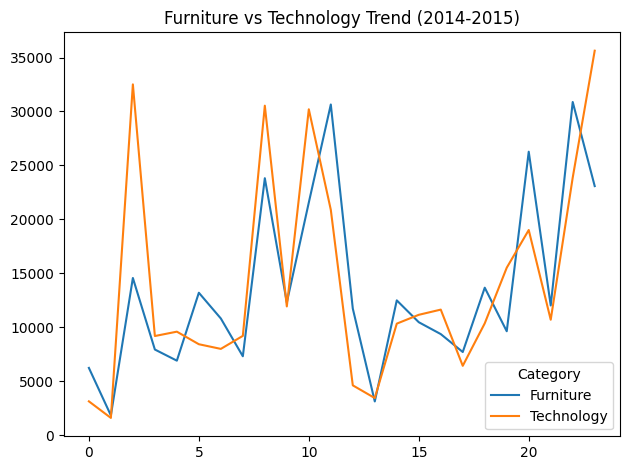

In [ ]:
task9 = pd.pivot_table(
    df[df["Year"].isin([2014,2015]) & df["Category"].isin(["Furniture","Technology"])],
    index=["Year","MonthNum","Month"], columns="Category",
    values="Sales", aggfunc="sum", fill_value=0
)
print(task9.head(13))

task9.reset_index(drop=True).plot(title="Furniture vs Technology Trend (2014-2015)")
plt.tight_layout()
plt.show()

In [ ]:
weekly = df.groupby("Week").agg(Sales=("Sales","sum"))
weekly["Growth %"] = weekly["Sales"].pct_change().mul(100).round(2)
print(weekly)

monthly = df.groupby(["Year","MonthNum","Month"]).agg(Sales=("Sales","sum"))
monthly["Growth %"] = monthly["Sales"].pct_change().mul(100).round(2)
print(monthly.head(13))

yearly = df.groupby("Year").agg(Sales=("Sales","sum"))
yearly["Growth %"] = yearly["Sales"].pct_change().mul(100).round(2)
print(yearly)

           Sales  Growth %
Week                      
1     26444.6286       NaN
2     17646.6940    -33.27
3     25955.6090     47.08
4     15366.7280    -40.80
5     33949.3880    120.93
6     11194.2240    -67.03
7     16763.8254     49.75
8     10891.3960    -35.03
9     25784.1394    136.74
10    40041.3170     55.29
11    25448.2920    -36.44
12    87274.1356    242.95
13    36557.6818    -58.11
14    37932.2915      3.76
15    30183.6840    -20.43
16    32441.5240      7.48
17    16860.7761    -48.03
18    40835.5918    142.19
19    30881.3390    -24.38
20    29214.7745     -5.40
21    39377.5790     34.79
22    43760.6494     11.13
23    31259.9330    -28.57
24    36047.0255     15.31
25    39199.3636      8.75
26    32374.3782    -17.41
27    31010.0250     -4.21
28    27159.3070    -12.42
29    29949.6160     10.27
30    48832.8610     63.05
31    18815.8700    -61.47
32    40113.5197    113.19
33    37922.0560     -5.46
34    40055.0778      5.62
35    58509.1925     46.07
3

In [ ]:
df.to_csv("orders_export.csv", index=False)
from google.colab import files
files.download("orders_export.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
original_cols = ['Row ID', 'OrderID', 'OrderDate', 'ShipDate', 'ShipMode', 'CustomerID',
                  'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code',
                  'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name',
                  'Sales', 'Quantity', 'Discount', 'Profit']

df[original_cols].to_csv("orders_export.csv", index=False)

from google.colab import files
files.download("orders_export.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import csv

original_cols = ['Row ID', 'OrderID', 'OrderDate', 'ShipDate', 'ShipMode', 'CustomerID',
                  'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code',
                  'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name',
                  'Sales', 'Quantity', 'Discount', 'Profit']

df[original_cols].to_csv("orders_export.csv", index=False, quoting=csv.QUOTE_ALL)

from google.colab import files
files.download("orders_export.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>